# Deep Learning HW 3 Part 4
Author: Daniel Bond

In [1]:
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ner_utils import (load_entities, label_names, comp_metric, hard_processing, bootstrap_ci, predict_locations, search_threshold,
                       word_spans, load_probs, ensemble_probs, make_submission)

seed = 67
np.random.seed(seed)

DATA_DIR = Path("data")
OUT_DIR = Path(".")  # preds/, subs/ and results.csv copied from Drive after Part 3
PRED_DIR, SUB_DIR, IMG_DIR = OUT_DIR / "preds", OUT_DIR / "subs", OUT_DIR / "images"
RU_ROWS, RU_VALID_EVERY = 300_000, 10  # as in Parts 2-3
LABELS = label_names(["LOC"])

uk_df = pd.read_csv(DATA_DIR / "uk_geo_dataset.csv")
ru_df = pd.read_csv(DATA_DIR / "ru_geo_dataset.csv", nrows=RU_ROWS)
sample_df = pd.read_csv(DATA_DIR / "labeling_sample.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")


def silver(df):
    texts = df["text"].tolist()
    return texts, [[t[a:b] for a, b in e["LOC"]] for t, e in zip(texts, load_entities(df, ["LOC"]))]


TEXTS, GOLD = {}, {}
TEXTS["uk_valid"], GOLD["uk_valid"] = silver(uk_df[uk_df["is_valid"] == 1])
TEXTS["ru_valid"], GOLD["ru_valid"] = silver(ru_df[ru_df["doc_id"] % RU_VALID_EVERY == 0])
TEXTS["sample"], GOLD["sample"] = sample_df["text"].tolist(), sample_df["locations"].map(eval).tolist()
TEXTS["test"] = test_df["text"].tolist()
WORDS = {name: [word_spans(t) for t in texts] for name, texts in TEXTS.items()}

results = pd.read_csv(OUT_DIR / "results.csv").set_index("name")
PROBS = {name: load_probs(PRED_DIR / f"{name}.npz") for name in results.index}
LB = pd.read_csv(OUT_DIR / "lb_scores.csv").set_index("name")["public_LB"]  # typed in after every submission
print(f"{len(PROBS)} runs loaded, {len(LB)} with a public LB score; evaluation sets: { {k: len(v) for k, v in TEXTS.items()} }")


def score(probs, name, **decode_kwargs):
    """Competition metric of word-level probabilities on one evaluation set."""
    return comp_metric(GOLD[name], predict_locations(TEXTS[name], WORDS[name], probs, LABELS, **decode_kwargs))

17 runs loaded, 19 with a public LB score; evaluation sets: {'uk_valid': 10000, 'ru_valid': 30072, 'sample': 26, 'test': 477}


Public LB scores of the Part 3 submissions are in `lb_scores.csv`

## Threshold optimization

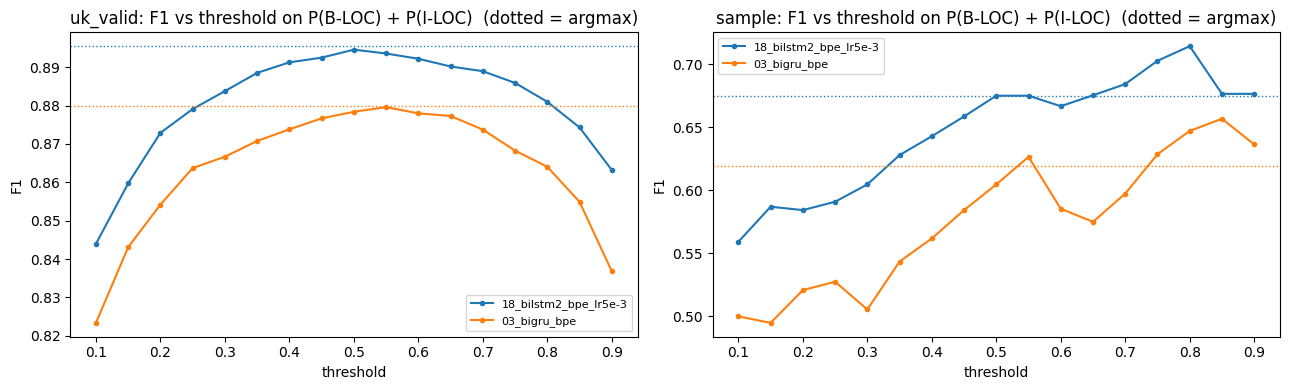

argmax  best threshold  best F1
18_bilstm2_bpe_lr5e-3 uk_valid  0.8955            0.50   0.8946
                      sample    0.6750            0.80   0.7143
03_bigru_bpe          uk_valid  0.8798            0.55   0.8796
                      sample    0.6190            0.85   0.6567

In [2]:
BEST = results["f1_uk_valid"].idxmax()
THRESHOLD_RUNS = list(dict.fromkeys([BEST, results["f1_sample"].idxmax(), "03_bigru_bpe"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
threshold_rows = {}
for run in THRESHOLD_RUNS:
    for ax, name in zip(axes, ["uk_valid", "sample"]):
        curve = search_threshold(TEXTS[name], WORDS[name], PROBS[run][name], LABELS, GOLD[name])
        grid = curve.drop("argmax")
        line, = ax.plot(grid.index.astype(float), grid.values, marker="o", ms=3, label=run)
        ax.axhline(curve["argmax"], color=line.get_color(), ls=":", lw=1)
        threshold_rows[(run, name)] = {"argmax": curve["argmax"], "best threshold": grid.idxmax(), "best F1": grid.max()}
for ax, name in zip(axes, ["uk_valid", "sample"]):
    ax.set(title=f"{name}: F1 vs threshold on P(B-LOC) + P(I-LOC)  (dotted = argmax)", xlabel="threshold", ylabel="F1")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(IMG_DIR / "thresholds.png", dpi=120, bbox_inches="tight")
plt.show()
pd.DataFrame(threshold_rows).T.round(4)

The threshold is chosen on `uk_valid`; the sample curve is shown only for comparison (26 texts are too few to tune on).

Results:
- On `uk_valid` argmax wins
- On the sample the optimum is higher, but due to low sample count it is unreliable to tune threshold based on it.

Decision: argmax

## Entity merging

In [ ]:
THRESHOLD = None

variants = {
    "lenient (I after O starts an entity)": dict(scheme="lenient"),
    "strict (I after O is dropped)": dict(scheme="strict"),
    "io (one entity per run of LOC tokens)": dict(scheme="io"),
    "lenient, no hyphen merge": dict(scheme="lenient", merge_hyphens=False),
    "lenient + bridge 'вул' . 'Name'": dict(scheme="lenient", bridge_dots=True),
    "lenient + bridge + house numbers": dict(scheme="lenient", bridge_dots=True, house_numbers=True),
    "lenient + strip symbols": dict(scheme="lenient", strip_symbols=True),
    "strict + strip symbols": dict(scheme="strict", strip_symbols=True),
    "lenient + strip symbols + bridge + house numbers": dict(scheme="lenient", strip_symbols=True, bridge_dots=True,
                                                            house_numbers=True),
}
merging = pd.DataFrame({
    label: {name: score(PROBS[BEST][name], name, threshold=THRESHOLD, **kwargs) for name in ["uk_valid", "ru_valid", "sample"]}
    for label, kwargs in variants.items()
}).T
print(BEST)
merging.round(4)

18_bilstm2_bpe_lr5e-3


,uk_valid,ru_valid,sample
lenient (I after O starts an entity),0.8955,0.9409,0.6750
strict (I after O is dropped),0.8966,0.9423,0.6835
io (one entity per run of LOC tokens),0.8856,0.9309,0.6750
"lenient, no hyphen merge",0.8955,0.9409,0.6750
lenient + bridge 'вул' . 'Name',0.8950,0.9409,0.6750
lenient + bridge + house numbers,0.8953,0.9409,0.6750
lenient + strip symbols,0.8955,0.9409,0.7000
strict + strip symbols,0.8966,0.9423,0.7089
lenient + strip symbols + bridge + house numbers,0.8953,0.9409,0.7000


In [ ]:
MERGING = dict(scheme="strict", strip_symbols=True) 

example = predict_locations(TEXTS["sample"], WORDS["sample"], PROBS[BEST]["sample"], LABELS, threshold=THRESHOLD, **MERGING)
norm = lambda strings: {hard_processing(s): s for s in strings}
errors = pd.DataFrame({
    "gold": GOLD["sample"], "predicted": example,
    "missed": [sorted(v for k, v in norm(g).items() if k not in norm(p)) for g, p in zip(GOLD["sample"], example)],
    "extra": [sorted(v for k, v in norm(p).items() if k not in norm(g)) for g, p in zip(GOLD["sample"], example)],
})
errors[(errors["missed"].str.len() > 0) | (errors["extra"].str.len() > 0)]

,gold,predicted,missed,extra
1,[Проспект Бандери],"[Бандери, Оболонь]",[Проспект Бандери],"[Бандери, Оболонь]"
2,"[Київщині, Чорнобиль, Київ, Тетерів, Фастів, Б...","[Київщині, Чорнобиль, Київ, Миронівка, Бориспі...","[Біла Церква, Тетерів, Фастів]",[]
5,[Києву],"[Києву, Україні]",[],[Україні]
6,[],[України],[],[України]
10,[Троєщині],"[Троєщині, Київ]",[],[Київ]
11,[Шевченківському районі],"[Шевченківському районі, Києва]",[],[Києва]
12,[Героїв Дніпра],"[Героїв Дніпра, Оболонь]",[],[Оболонь]
18,"[Києвом, Васильковом]","[Києвом, Васильковом, Приміського вокзалу Київ...",[],"[Боярка, Васильків-Центр, Васильків-Центр та п..."
19,[Києва],"[Києва, Хуйовий]",[],[Хуйовий]
21,[],"[України, Київ]",[],"[Київ, України]"


Results for the best model:
`strict` + symbol stripping is the best variant on all three sets and is used for the tuned submission and the ensembles.

Errors of the best model on the sample: generic mentions didn't get marked, a street name cutting the street type, three missed towns in a list, and a swear word taken for a location (I guess it is used as a direction in some contexts, but that certainly didn't help with the task). 

Most errors are from what counts as a location, not from finding names.

## Ensembling

In [ ]:
ranked = results["f1_uk_valid"].sort_values(ascending=False).index.tolist()
ENSEMBLES = {f"ens_top{k}": ranked[:k] for k in (2, 3, 5)}
ENSEMBLES["ens_diverse"] = ["18_bilstm2_bpe_lr5e-3", "08_bilstm2_bpe_posts", "12_bilstm2_word_fasttext_frozen",
                            "09_bigru2_bpe_posts_loc"]
lb_ranked = LB[LB.index.isin(results.index)].sort_values(ascending=False).index.tolist()
ENSEMBLES.update({f"ens_lb_top{k}": lb_ranked[:k] for k in (3, 5)})
ENSEMBLE_WEIGHTS = {name: None for name in ENSEMBLES}
ENSEMBLE_WEIGHTS["ens_top5_weighted"] = results.loc[ranked[:5], "f1_uk_valid"].tolist()
ENSEMBLES["ens_top5_weighted"] = ranked[:5]

ENS_PROBS = {
    ens: {name: ensemble_probs([PROBS[m][name] for m in members], ENSEMBLE_WEIGHTS[ens]) for name in TEXTS}
    for ens, members in ENSEMBLES.items()
}
rows = {}
for ens, members in ENSEMBLES.items():
    pred_sample = predict_locations(TEXTS["sample"], WORDS["sample"], ENS_PROBS[ens]["sample"], LABELS,
                                    threshold=THRESHOLD, **MERGING)
    low, high = bootstrap_ci(GOLD["sample"], pred_sample)
    rows[ens] = {"members": ", ".join(m[:2] for m in members),
                 **{f"f1_{name}": score(ENS_PROBS[ens][name], name, threshold=THRESHOLD, **MERGING)
                    for name in ["uk_valid", "ru_valid", "sample"]},
                 "sample_ci_low": low, "sample_ci_high": high,
                 "best single f1_uk_valid": max(score(PROBS[m]["uk_valid"], "uk_valid", threshold=THRESHOLD, **MERGING)
                                                for m in members)}
ensembles = pd.DataFrame(rows).T
ensembles

,members,f1_uk_valid,f1_ru_valid,f1_sample,sample_ci_low,sample_ci_high,best single f1_uk_valid
ens_top2,"18, 11",0.906461,0.961506,0.702703,0.55383,0.875,0.896605
ens_top3,"18, 11, 13",0.904977,0.956999,0.72,0.566641,0.875,0.896605
ens_top5,"18, 11, 13, 14, 19",0.901882,0.95412,0.675325,0.520826,0.837209,0.896605
ens_diverse,"18, 08, 12, 09",0.903216,0.956073,0.623377,0.482727,0.8,0.896605
ens_lb_top3,"18, 12, 08",0.901875,0.953847,0.648649,0.5,0.830769,0.896605
ens_lb_top5,"18, 12, 08, 09, 10",0.901992,0.958386,0.623377,0.482727,0.8,0.896605
ens_top5_weighted,"18, 11, 13, 14, 19",0.902193,0.95412,0.675325,0.520826,0.837209,0.896605


Ensembling: a weighted mean of the word-level probabilities of several models, then the same threshold and merging as for a single model.

Results:
- Every ensemble beats its best member on valid. The best is `ens_top2` (BPE BiLSTM 18 + word-level fastText BiLSTM 11)
- More members don't help

`ens_top2` is submitted as the ensemble.

## Submissions

In [ ]:
tuned = {f"{BEST}_tuned": PROBS[BEST]["test"], **{ens: probs["test"] for ens, probs in ENS_PROBS.items()}}
for name, probs in tuned.items():
    pred = predict_locations(TEXTS["test"], WORDS["test"], probs, LABELS, threshold=THRESHOLD, **MERGING)
    make_submission(test_df, pred, SUB_DIR / f"{name}.csv")
    print(f"{name}: {sum(map(len, pred))} locations in {sum(bool(p) for p in pred)} of {len(pred)} texts")
print("\nkaggle competitions submit -c kse-ua-location-extraction-2026 -f subs/<name>.csv -m <name>")

18_bilstm2_bpe_lr5e-3_tuned: 818 locations in 333 of 477 texts
ens_top2: 762 locations in 328 of 477 texts
ens_top3: 786 locations in 331 of 477 texts
ens_top5: 801 locations in 333 of 477 texts
ens_diverse: 800 locations in 338 of 477 texts
ens_lb_top3: 793 locations in 335 of 477 texts
ens_lb_top5: 795 locations in 337 of 477 texts
ens_top5_weighted: 801 locations in 333 of 477 texts

kaggle competitions submit -c kse-ua-location-extraction-2026 -f subs/<name>.csv -m <name>


## CV vs LB

In [7]:
table = pd.concat([
    results[["f1_uk_valid", "f1_ru_valid", "f1_sample", "sample_ci_low", "sample_ci_high"]],
    ensembles[["f1_uk_valid", "f1_ru_valid", "f1_sample", "sample_ci_low", "sample_ci_high"]].astype(float),
    pd.DataFrame({f"{BEST}_tuned": {
        **{f"f1_{name}": score(PROBS[BEST][name], name, threshold=THRESHOLD, **MERGING) for name in ["uk_valid", "ru_valid", "sample"]},
    }}).T,
])
table["public_LB"] = LB
table.to_csv(OUT_DIR / "cv_vs_lb.csv")
table.round(4)

,f1_uk_valid,f1_ru_valid,f1_sample,sample_ci_low,sample_ci_high,public_LB
01_gru_word,0.8449,0.8822,0.4500,0.2623,0.6265,0.4714
02_bigru_word,0.8729,0.9122,0.4878,0.3158,0.6757,0.5127
03_bigru_bpe,0.8798,0.9281,0.6190,0.4680,0.7359,0.5343
04_bigru2_bpe,0.8847,0.9289,0.5977,0.4415,0.7273,0.5152
05_bilstm_bpe,0.8817,0.9327,0.6341,0.4706,0.7750,0.5340
06_bilstm2_bpe,0.8870,0.9357,0.6329,0.4675,0.7664,0.5593
07_bigru2_bpe_posts,0.8810,0.9271,0.5789,0.4615,0.7213,0.5508
08_bilstm2_bpe_posts,0.8856,0.9334,0.5897,0.4444,0.7797,0.5629
09_bigru2_bpe_posts_loc,0.8763,0.9335,0.5789,0.4411,0.7576,0.5609
10_bilstm2_word,0.8788,0.9287,0.6494,0.5151,0.7797,0.5604


Valid F1 is ~0.90, the LB ~0.59. The model is validated on news sentences with labels produced by another model and tested on Telegram posts labelled by people with a wider definition of a location and a narrower one for generic mentions. The sample is closer to the LB, but 26 texts are too few to select models.

Is the model adequate? Yes, for an RNN. The best single model is above `ukr_rnn_baseline` (0.551), and the ensemble (0.594) reaches `nlp_ua_bert_baseline` (0.593). It finds cities and regions reliably.

Final submissions: `ens_top2` and `18_bilstm2_bpe_lr5e-3_tuned` - the best ensemble and the best single model by validation, which are also the best two on the public LB.

PS. I've spent the last submission of 15-th Nov (deadline date), 20-th submission total, on such test: I wanted to check the assumption I made that I cannot tune thresholds on sample (well it seemed obvious, there is only 26 examples, that's pure noise). BUT: raising the threshold, as was shown beneficial for sample data F1 score, raised public LB F1 score by 0.01! That's a solid free boost achieved just by going slightly wrong way :P